In [8]:
import pandas as pd

url = "https://data.cityofnewyork.us/api/views/f9bf-2cp4/rows.csv"
df = pd.read_csv(url)
df.head()

,DBN,SCHOOL NAME,Num of SAT Test Takers,SAT Critical Reading Avg. Score,SAT Math Avg. Score,SAT Writing Avg. Score
0,01M292,HENRY STREET SCHOOL FOR INTERNATIONAL STUDIES,29,355,404,363
1,01M448,UNIVERSITY NEIGHBORHOOD HIGH SCHOOL,91,383,423,366
2,01M450,EAST SIDE COMMUNITY SCHOOL,70,377,402,370
3,01M458,FORSYTH SATELLITE ACADEMY,7,414,401,359
4,01M509,MARTA VALLE HIGH SCHOOL,44,390,433,384


In [9]:
score_cols = ["SAT Critical Reading Avg. Score",
              "SAT Math Avg. Score",
              "SAT Writing Avg. Score"]

for col in score_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Schools before cleaning:", len(df))
df = df.dropna(subset=score_cols)
print("Schools after cleaning:", len(df))

Schools before cleaning: 478
Schools after cleaning: 421


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["SAT Critical Reading Avg. Score", "SAT Writing Avg. Score"]]
y = df["SAT Math Avg. Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Average error (points):", round(mean_absolute_error(y_test, predictions), 1))
print("R² score:", round(r2_score(y_test, predictions), 2))

Average error (points): 21.0
R² score: 0.78


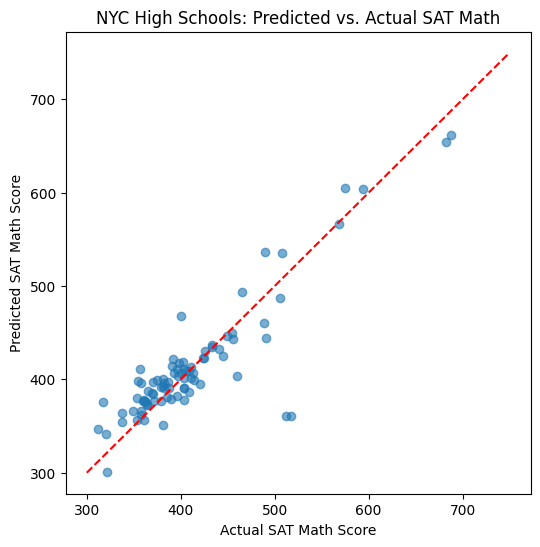

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.6)
plt.plot([300, 750], [300, 750], color="red", linestyle="--")
plt.xlabel("Actual SAT Math Score")
plt.ylabel("Predicted SAT Math Score")
plt.title("NYC High Schools: Predicted vs. Actual SAT Math")
plt.show()